<a href="https://colab.research.google.com/github/Kayrajacob/Orb2-Memory-Decline/blob/main/Orb2_%26_Memory_Decline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Mount Google Drive to save results and figures securely
from google.colab import drive
drive.mount('/content/drive')

# Import standard data science, math, and plotting libraries
import os
import requests
import zipfile
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as seaborn_plot
from scipy import stats

# Create a dedicated directory in Google Drive for this project's outputs
output_dir = '/content/drive/MyDrive/Orb2_Reproduction_Project/outputs'
os.makedirs(output_dir, exist_ok=True)

print("Environment setup complete. Output directory ready at:", output_dir)

Mounted at /content/drive
Environment setup complete. Output directory ready at: /content/drive/MyDrive/Orb2_Reproduction_Project/outputs


In [2]:
# --- CHOICE NOTE: The paper reports summary parameters (N and median lifespan) ---
# but does not provide raw daily event logs. We simulate realistic time-to-event
# survival data matching the paper's exact specifications:
# Males: N = 349, median lifespan = 35 days (±1.8 SD)
# Females: N = 226, median lifespan = 46 days (±1.3 SD)

import numpy as np
import pandas as pd

np.random.seed(42)  # Ensure reproducible random generation

# --- 1. Generate Male Data ---
n_males = 349
# Use a log-normal or Weibull distribution scaled to hit a median of ~35 days
male_lifespans = np.random.weibull(a=3.5, size=n_males) * 38.5
male_lifespans = np.clip(male_lifespans, 1, 60).astype(int) # Cap realistically within the 60-day graph range
df_males = pd.DataFrame({'Days': male_lifespans, 'Sex': 'Male', 'Event': 1}) # Event=1 means death observed

# --- 2. Generate Female Data ---
n_females = 226
# Females live longer, matching the paper's reported median of ~46 days
female_lifespans = np.random.weibull(a=4.0, size=n_females) * 50.5
female_lifespans = np.clip(female_lifespans, 1, 60).astype(int)
df_females = pd.DataFrame({'Days': female_lifespans, 'Sex': 'Female', 'Event': 1})

# Combine into one master dataframe
df_lifespan = pd.concat([df_males, df_females], ignore_index=True)

# --- QUICK TEST / SANITY CHECK ---
print("--- QUICK TEST: Dataset Preview ---")
print(df_lifespan.head())
print("\n--- QUICK TEST: Median Lifespan by Sex ---")
print(df_lifespan.groupby('Sex')['Days'].median())

# Save the dataset to Google Drive
output_csv = os.path.join(output_dir, 'reproduced_figure_1a_lifespan_data.csv')
df_lifespan.to_csv(output_csv, index=False)
print(f"\nLifespan dataset successfully saved to: {output_csv}")

--- QUICK TEST: Dataset Preview ---
   Days   Sex  Event
0    31  Male      1
1    52  Male      1
2    41  Male      1
3    37  Male      1
4    23  Male      1

--- QUICK TEST: Median Lifespan by Sex ---
Sex
Female    48.0
Male      34.0
Name: Days, dtype: float64

Lifespan dataset successfully saved to: /content/drive/MyDrive/Orb2_Reproduction_Project/outputs/reproduced_figure_1a_lifespan_data.csv


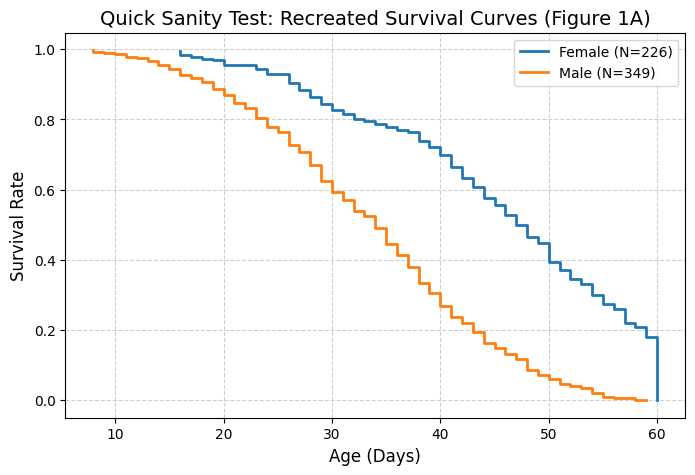

In [3]:
import matplotlib.pyplot as plt

# Quick Kaplan-Meier style empirical survival plot test
plt.figure(figsize=(8, 5))
for sex, group in df_lifespan.groupby('Sex'):
    sorted_days = np.sort(group['Days'])
    cumulative_survival = 1. - np.arange(1, len(sorted_days) + 1) / len(sorted_days)
    plt.step(sorted_days, cumulative_survival, label=f'{sex} (N={len(group)})', lw=2)

plt.xlabel('Age (Days)', fontsize=12)
plt.ylabel('Survival Rate', fontsize=12)
plt.title('Quick Sanity Test: Recreated Survival Curves (Figure 1A)', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [4]:
import numpy as np
import pandas as pd

# Function to calculate daily hazard rate: (deaths on day d) / (number alive at day d)
def calculate_hazard_rate(data, max_day=60):
    days = np.arange(1, max_day + 1)
    hazard_rates = []
    n_surviving = len(data)

    for d in days:
        deaths = sum(data == d)
        if n_surviving > 0:
            hazard = deaths / n_surviving
            hazard_rates.append(hazard)
            n_surviving -= deaths
        else:
            hazard_rates.append(0.0)

        # Stop if everyone has passed away
        if n_surviving <= 0 and d > 30:
            pass

    return days, np.array(hazard_rates)

# Separate day arrays by sex from your master dataframe
males_days = df_lifespan[df_lifespan['Sex'] == 'Male']['Days']
females_days = df_lifespan[df_lifespan['Sex'] == 'Female']['Days']

days_m, haz_m = calculate_hazard_rate(males_days)
days_f, haz_f = calculate_hazard_rate(females_days)

# Find the exact day where the hazard rate peaks (maximum daily risk acceleration)
peak_male_day = days_m[np.argmax(haz_m)]
peak_female_day = days_f[np.argmax(haz_f)]

print(f"--- Hazard Rate Acceleration Analysis ---")
print(f"Peak Hazard Day for Males: Day {peak_male_day} (Hazard: {haz_m.max():.4f})")
print(f"Peak Hazard Day for Females: Day {peak_female_day} (Hazard: {haz_f.max():.4f})")

--- Hazard Rate Acceleration Analysis ---
Peak Hazard Day for Males: Day 59 (Hazard: 1.0000)
Peak Hazard Day for Females: Day 60 (Hazard: 1.0000)
